In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

DATA_DIR = Path("Sequential_Peptides")

train_path = DATA_DIR / "train_seqs.csv"
valid_path = DATA_DIR / "valid_seqs.csv"
test_path = DATA_DIR / "test_seqs.csv"

train_df = pd.read_csv(train_path)
valid_df = pd.read_csv(valid_path)
test_df = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Valid shape:", valid_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain columns:", list(train_df.columns))

print("\nTraining samples:")
display(train_df.head())

Train shape: (54159, 3)
Valid shape: (4000, 3)
Test shape: (4000, 3)

Train columns: ['Unnamed: 0', 'Feature', 'Label']

Training samples:


,Unnamed: 0,Feature,Label
0,0,NACFTMR,1.687
1,1,MQLVD,1.710
2,2,RTCERVNPLE,1.659
3,3,TWCCTTF,2.020
4,4,LAPRPQGLKG,1.524


In [2]:
for name, dataframe in {
    "train": train_df,
    "valid": valid_df,
    "test": test_df
}.items():
    print(f"\n===== {name.upper()} =====")
    print("Shape:", dataframe.shape)
    print("Missing values:")
    display(dataframe.isna().sum())

    print("Duplicated rows:", dataframe.duplicated().sum())

    print("Sequence length range:",
          dataframe["Feature"].str.len().min(),
          "-",
          dataframe["Feature"].str.len().max())

    print("Label summary:")
    display(dataframe["Label"].describe())


===== TRAIN =====
Shape: (54159, 3)
Missing values:


Unnamed: 0    0
Feature       0
Label         0
dtype: int64

Duplicated rows: 0
Sequence length range: 5 - 10
Label summary:


count    54159.000000
mean         1.738762
std          0.211196
min          0.993000
25%          1.625000
50%          1.751000
75%          1.871000
max          2.619000
Name: Label, dtype: float64


===== VALID =====
Shape: (4000, 3)
Missing values:


Unnamed: 0    0
Feature       0
Label         0
dtype: int64

... (2 outputs left out)


===== TEST =====
Shape: (4000, 3)
Missing values:


Unnamed: 0    0
Feature       0
Label         0
dtype: int64

Duplicated rows: 0
Sequence length range: 5 - 10
Label summary:


count    4000.000000
mean        1.744751
std         0.211390
min         1.027000
25%         1.632000
50%         1.760000
75%         1.879000
max         2.428000
Name: Label, dtype: float64

In [3]:
train_sequences = set(train_df["Feature"])
valid_sequences = set(valid_df["Feature"])
test_sequences = set(test_df["Feature"])

print("Train ∩ Valid:", len(train_sequences & valid_sequences))
print("Train ∩ Test:", len(train_sequences & test_sequences))
print("Valid ∩ Test:", len(valid_sequences & test_sequences))

Train ∩ Valid: 1
Train ∩ Test: 3
Valid ∩ Test: 0


In [4]:
for dataframe in [train_df, valid_df, test_df]:
    dataframe.drop(
        columns=["Unnamed: 0"],
        errors="ignore",
        inplace=True
    )

train_sequences = set(train_df["Feature"])
valid_sequences = set(valid_df["Feature"])
test_sequences = set(test_df["Feature"])

print("Before cleaning:")
print("Train ∩ Valid:", len(train_sequences & valid_sequences))
print("Train ∩ Test:", len(train_sequences & test_sequences))
print("Valid ∩ Test:", len(valid_sequences & test_sequences))

valid_df = valid_df[
    ~valid_df["Feature"].isin(train_sequences)
].copy()

test_df = test_df[
    ~test_df["Feature"].isin(train_sequences)
].copy()

test_df = test_df[
    ~test_df["Feature"].isin(set(valid_df["Feature"]))
].copy()

print("\nAfter cleaning:")
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Test:", test_df.shape)

print("Train ∩ Valid:", len(set(train_df["Feature"]) & set(valid_df["Feature"])))
print("Train ∩ Test:", len(set(train_df["Feature"]) & set(test_df["Feature"])))
print("Valid ∩ Test:", len(set(valid_df["Feature"]) & set(test_df["Feature"])))

Before cleaning:
Train ∩ Valid: 1
Train ∩ Test: 3
Valid ∩ Test: 0

After cleaning:
Train: (54159, 2)
Validation: (3999, 2)
Test: (3997, 2)
Train ∩ Valid: 0
Train ∩ Test: 0
Valid ∩ Test: 0


In [5]:
AMINO_ACIDS = list("ACDEFGHIKLMNPQRSTVWY")

def encode_aac(sequence: str) -> np.ndarray:
    """
    Convert a peptide sequence into a 20-dimensional
    amino-acid composition vector.
    """
    sequence = str(sequence).strip().upper()

    if len(sequence) == 0:
        raise ValueError("Empty peptide sequence encountered.")

    counts = Counter(sequence)

    return np.array(
        [
            counts.get(amino_acid, 0) / len(sequence)
            for amino_acid in AMINO_ACIDS
        ],
        dtype=float
    )

In [6]:
def build_feature_matrix(dataframe: pd.DataFrame) -> np.ndarray:
    return np.vstack(
        dataframe["Feature"].map(encode_aac)
    )

X_train = build_feature_matrix(train_df)
X_valid = build_feature_matrix(valid_df)
X_test = build_feature_matrix(test_df)

y_train = train_df["Label"].to_numpy(dtype=float)
y_valid = valid_df["Label"].to_numpy(dtype=float)
y_test = test_df["Label"].to_numpy(dtype=float)

print("X_train shape:", X_train.shape)
print("X_valid shape:", X_valid.shape)
print("X_test shape:", X_test.shape)

print("\ny_train shape:", y_train.shape)
print("y_valid shape:", y_valid.shape)
print("y_test shape:", y_test.shape)

X_train shape: (54159, 20)
X_valid shape: (3999, 20)
X_test shape: (3997, 20)

y_train shape: (54159,)
y_valid shape: (3999,)
y_test shape: (3997,)


In [7]:
baseline_prediction = np.full(
    shape=len(y_test),
    fill_value=y_train.mean()
)

naive_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

naive_rmse = mean_squared_error(
    y_test,
    baseline_prediction
) ** 0.5

naive_r2 = r2_score(
    y_test,
    baseline_prediction
)

print("Naive Mean Baseline")
print("MAE:", naive_mae)
print("RMSE:", naive_rmse)
print("R2:", naive_r2)

Naive Mean Baseline
MAE: 0.16047615248078168
RMSE: 0.21123468308334237
R2: -0.0008418438401884831


In [8]:
def evaluate_regression_model(
    model_name: str,
    model,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_valid: np.ndarray,
    y_valid: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray
):
    model.fit(X_train, y_train)

    valid_prediction = model.predict(X_valid)
    test_prediction = model.predict(X_test)

    result = {
        "model": model_name,

        "valid_MAE": mean_absolute_error(
            y_valid,
            valid_prediction
        ),

        "valid_RMSE": mean_squared_error(
            y_valid,
            valid_prediction
        ) ** 0.5,

        "valid_R2": r2_score(
            y_valid,
            valid_prediction
        ),

        "test_MAE": mean_absolute_error(
            y_test,
            test_prediction
        ),

        "test_RMSE": mean_squared_error(
            y_test,
            test_prediction
        ) ** 0.5,

        "test_R2": r2_score(
            y_test,
            test_prediction
        )
    }

    return result, test_prediction

In [9]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(
        alpha=1.0
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Histogram Gradient Boosting": HistGradientBoostingRegressor(
        random_state=42
    )
}

In [10]:
results = []

test_predictions = {}

trained_models = {}

for model_name, model in models.items():
    print(f"Training: {model_name}")

    result, test_prediction = evaluate_regression_model(
        model_name=model_name,
        model=model,
        X_train=X_train,
        y_train=y_train,
        X_valid=X_valid,
        y_valid=y_valid,
        X_test=X_test,
        y_test=y_test
    )

    results.append(result)

    test_predictions[model_name] = test_prediction
    trained_models[model_name] = model

results_df = (
    pd.DataFrame(results)
    .sort_values("test_MAE")
    .reset_index(drop=True)
)

display(results_df)

Training: Linear Regression
Training: Ridge Regression
Training: Random Forest
Training: Histogram Gradient Boosting


,model,valid_MAE,valid_RMSE,valid_R2,test_MAE,test_RMSE,test_R2
0,Histogram Gradient Boosting,0.056446,0.074438,0.872518,0.056710,0.074244,0.876361
1,Random Forest,0.060937,0.079915,0.853066,0.061849,0.079861,0.856945
2,Ridge Regression,0.084724,0.111348,0.714749,0.084215,0.111884,0.719214
3,Linear Regression,0.084758,0.111350,0.714742,0.084238,0.111882,0.719229


In [11]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

In [12]:
results_df.to_csv(
    results_dir / "aac_classical_baselines.csv",
    index=False
)

print("Saved to:")
print(results_dir / "aac_classical_baselines.csv")

Saved to:
results\aac_classical_baselines.csv


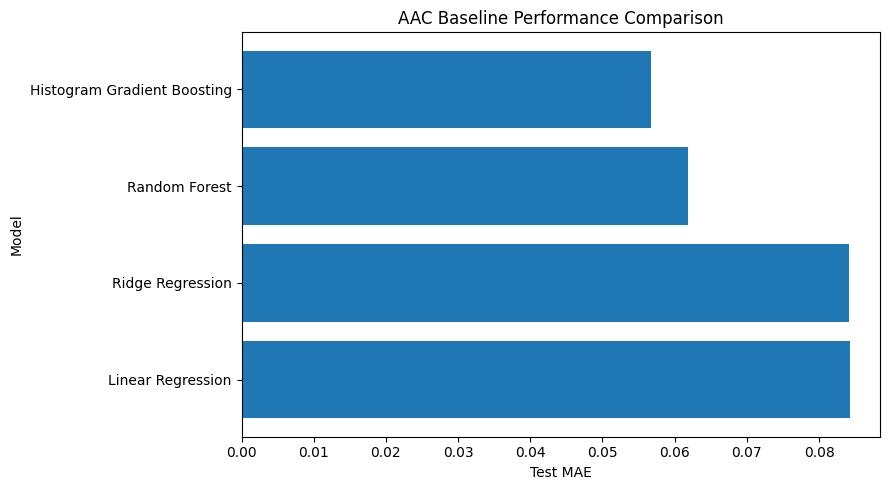

In [13]:
figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

plot_data = results_df.sort_values(
    "test_MAE",
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_data["model"],
    plot_data["test_MAE"]
)

plt.xlabel("Test MAE")
plt.ylabel("Model")
plt.title("AAC Baseline Performance Comparison")

plt.tight_layout()

plt.savefig(
    figures_dir / "aac_baseline_mae_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [14]:
random_forest_model = trained_models["Random Forest"]

importance_df = pd.DataFrame({
    "amino_acid": AMINO_ACIDS,
    "importance": random_forest_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

display(importance_df)

,amino_acid,importance
18,W,0.176725
4,F,0.139687
19,Y,0.119736
3,E,0.082248
6,H,0.076506
2,D,0.071059
14,R,0.045835
8,K,0.041324
13,Q,0.038115
11,N,0.032188


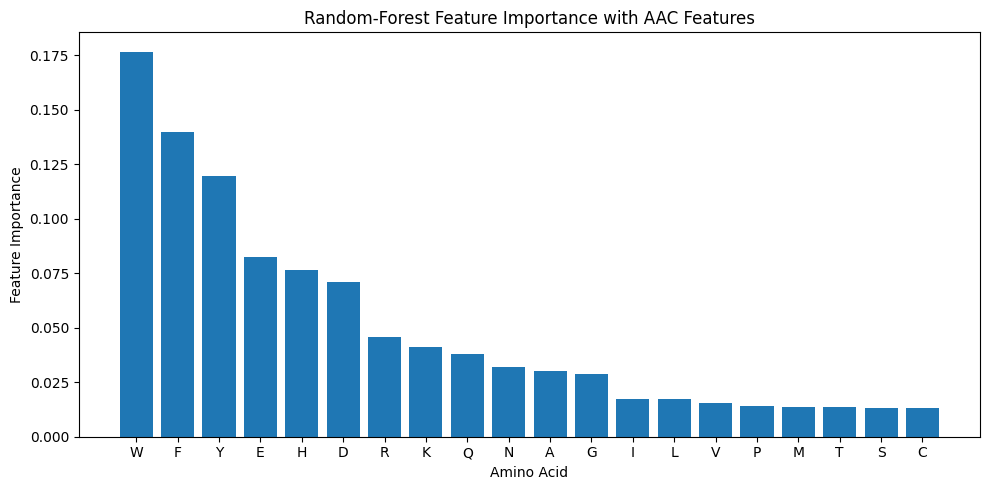

In [15]:
plt.figure(figsize=(10, 5))

plt.bar(
    importance_df["amino_acid"],
    importance_df["importance"]
)

plt.xlabel("Amino Acid")
plt.ylabel("Feature Importance")
plt.title("Random-Forest Feature Importance with AAC Features")

plt.tight_layout()
plt.show()

In [16]:
best_model_name = results_df.iloc[0]["model"]

best_prediction = test_predictions[best_model_name]

print("Best model:", best_model_name)

Best model: Histogram Gradient Boosting


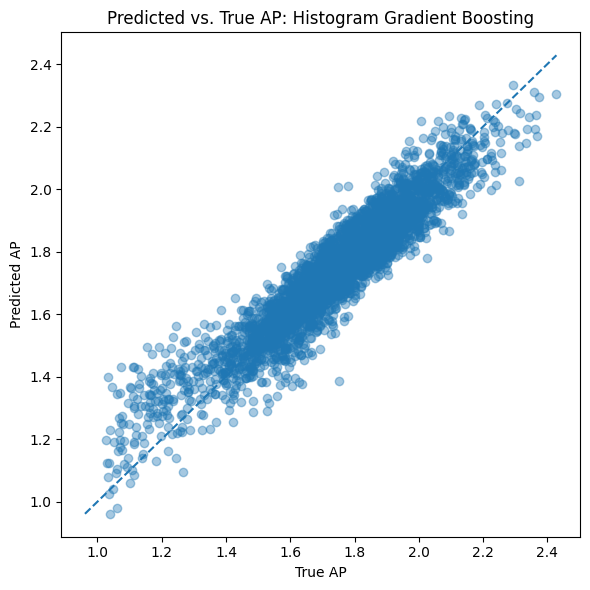

In [17]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    best_prediction,
    alpha=0.4
)

minimum_value = min(
    y_test.min(),
    best_prediction.min()
)

maximum_value = max(
    y_test.max(),
    best_prediction.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("True AP")
plt.ylabel("Predicted AP")
plt.title(f"Predicted vs. True AP: {best_model_name}")

plt.tight_layout()
plt.show()

In [18]:
error_analysis_df = test_df.copy()

error_analysis_df["prediction"] = best_prediction

error_analysis_df["absolute_error"] = np.abs(
    error_analysis_df["Label"]
    - error_analysis_df["prediction"]
)

error_analysis_df["sequence_length"] = (
    error_analysis_df["Feature"].str.len()
)

display(
    error_analysis_df
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
)

,Feature,Label,prediction,absolute_error,sequence_length
3731,TKKED,1.752,1.385997,0.366003,5
3307,DGALPG,1.033,1.397948,0.364948,6
2095,EELEH,1.072,1.430225,0.358225,5
299,IDDAH,1.153,1.494102,0.341102,5
2481,GAEPS,1.044,1.368012,0.324012,5
2115,MVEPN,1.111,1.429340,0.318340,5
2812,CARAI,1.114,1.432172,0.318172,5
1134,QQDQY,1.244,1.562087,0.318087,5
3460,EVNMK,1.190,1.493274,0.303274,5
3392,VQDMP,1.171,1.470997,0.299997,5


# Stage 2B: Positional One-Hot Encoding

In [19]:
AMINO_ACIDS = list("ACDEFGHIKLMNPQRSTVWY")

AA_TO_INDEX = {
    amino_acid: index
    for index, amino_acid in enumerate(AMINO_ACIDS)
}

MAX_LENGTH = 10

def encode_positional_one_hot(sequence: str) -> np.ndarray:
    """
    Convert a peptide sequence into a flattened positional
    one-hot vector with shape MAX_LENGTH * 20.
    """
    sequence = str(sequence).strip().upper()

    if len(sequence) == 0:
        raise ValueError("Empty peptide sequence encountered.")

    if len(sequence) > MAX_LENGTH:
        raise ValueError(
            f"Sequence is too long: {sequence}"
        )

    encoding = np.zeros(
        shape=(MAX_LENGTH, len(AMINO_ACIDS)),
        dtype=float
    )

    for position, amino_acid in enumerate(sequence):
        if amino_acid not in AA_TO_INDEX:
            raise ValueError(
                f"Unexpected amino acid: {amino_acid}"
            )

        encoding[
            position,
            AA_TO_INDEX[amino_acid]
        ] = 1.0

    return encoding.flatten()

In [20]:
def build_positional_feature_matrix(
    dataframe: pd.DataFrame
) -> np.ndarray:
    return np.vstack(
        dataframe["Feature"].map(
            encode_positional_one_hot
        )
    )

X_train_pos = build_positional_feature_matrix(
    train_df
)

X_valid_pos = build_positional_feature_matrix(
    valid_df
)

X_test_pos = build_positional_feature_matrix(
    test_df
)

print("X_train_pos shape:", X_train_pos.shape)
print("X_valid_pos shape:", X_valid_pos.shape)
print("X_test_pos shape:", X_test_pos.shape)

X_train_pos shape: (54159, 200)
X_valid_pos shape: (3999, 200)
X_test_pos shape: (3997, 200)


In [21]:
positional_models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(
        alpha=1.0
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Histogram Gradient Boosting": HistGradientBoostingRegressor(
        random_state=42
    )
}

In [22]:
positional_results = []

positional_test_predictions = {}

positional_trained_models = {}

for model_name, model in positional_models.items():
    print(f"Training: {model_name}")

    result, test_prediction = evaluate_regression_model(
        model_name=model_name,
        model=model,
        X_train=X_train_pos,
        y_train=y_train,
        X_valid=X_valid_pos,
        y_valid=y_valid,
        X_test=X_test_pos,
        y_test=y_test
    )

    positional_results.append(result)

    positional_test_predictions[
        model_name
    ] = test_prediction

    positional_trained_models[
        model_name
    ] = model

positional_results_df = (
    pd.DataFrame(positional_results)
    .sort_values("test_MAE")
    .reset_index(drop=True)
)

display(positional_results_df)

Training: Linear Regression
Training: Ridge Regression
Training: Histogram Gradient Boosting


,model,valid_MAE,valid_RMSE,valid_R2,test_MAE,test_RMSE,test_R2
0,Histogram Gradient Boosting,0.077500,0.104017,0.751076,0.078371,0.105258,0.751489
1,Ridge Regression,0.086238,0.116984,0.685143,0.086254,0.118031,0.687515
2,Linear Regression,0.086240,0.116983,0.685148,0.086263,0.118035,0.687496
3,Random Forest,0.095007,0.121585,0.659891,0.095152,0.122166,0.665236


In [23]:
def encode_combined_features(sequence: str) -> np.ndarray:
    sequence = str(sequence).strip().upper()

    aac_features = encode_aac(sequence)

    positional_features = encode_positional_one_hot(sequence)

    normalized_length = np.array(
        [len(sequence) / MAX_LENGTH],
        dtype=float
    )

    return np.concatenate(
        [
            aac_features,
            positional_features,
            normalized_length
        ]
    )

In [24]:
def build_combined_feature_matrix(
    dataframe: pd.DataFrame
) -> np.ndarray:
    return np.vstack(
        dataframe["Feature"].map(
            encode_combined_features
        )
    )

X_train_combined = build_combined_feature_matrix(train_df)
X_valid_combined = build_combined_feature_matrix(valid_df)
X_test_combined = build_combined_feature_matrix(test_df)

print("X_train_combined:", X_train_combined.shape)
print("X_valid_combined:", X_valid_combined.shape)
print("X_test_combined:", X_test_combined.shape)

X_train_combined: (54159, 221)
X_valid_combined: (3999, 221)
X_test_combined: (3997, 221)


In [25]:
combined_models = {
    "Ridge Regression": Ridge(
        alpha=1.0
    ),

    "Histogram Gradient Boosting": HistGradientBoostingRegressor(
        random_state=42
    )
}

combined_results = []

for model_name, model in combined_models.items():
    print(f"Training: {model_name}")

    result, test_prediction = evaluate_regression_model(
        model_name=model_name,
        model=model,
        X_train=X_train_combined,
        y_train=y_train,
        X_valid=X_valid_combined,
        y_valid=y_valid,
        X_test=X_test_combined,
        y_test=y_test
    )

    combined_results.append(result)

combined_results_df = pd.DataFrame(
    combined_results
).sort_values("test_MAE")

display(combined_results_df)

Training: Ridge Regression
Training: Histogram Gradient Boosting


,model,valid_MAE,valid_RMSE,valid_R2,test_MAE,test_RMSE,test_R2
1,Histogram Gradient Boosting,0.051889,0.068614,0.891686,0.052545,0.069268,0.892379
0,Ridge Regression,0.072453,0.098818,0.775337,0.073921,0.101128,0.770606


In [26]:
aac_results_for_comparison = results_df.copy()
aac_results_for_comparison["encoding"] = "AAC"

positional_results_for_comparison = positional_results_df.copy()
positional_results_for_comparison["encoding"] = "Positional One-Hot"

combined_results_for_comparison = combined_results_df.copy()
combined_results_for_comparison["encoding"] = "Combined Features"

final_classical_comparison_df = pd.concat(
    [
        aac_results_for_comparison,
        positional_results_for_comparison,
        combined_results_for_comparison
    ],
    ignore_index=True
)

display(
    final_classical_comparison_df[
        [
            "encoding",
            "model",
            "test_MAE",
            "test_RMSE",
            "test_R2"
        ]
    ].sort_values("test_MAE")
)

final_classical_comparison_df.to_csv(
    results_dir / "classical_model_comparison.csv",
    index=False
)

,encoding,model,test_MAE,test_RMSE,test_R2
8,Combined Features,Histogram Gradient Boosting,0.052545,0.069268,0.892379
0,AAC,Histogram Gradient Boosting,0.056710,0.074244,0.876361
1,AAC,Random Forest,0.061849,0.079861,0.856945
9,Combined Features,Ridge Regression,0.073921,0.101128,0.770606
4,Positional One-Hot,Histogram Gradient Boosting,0.078371,0.105258,0.751489
2,AAC,Ridge Regression,0.084215,0.111884,0.719214
3,AAC,Linear Regression,0.084238,0.111882,0.719229
5,Positional One-Hot,Ridge Regression,0.086254,0.118031,0.687515
6,Positional One-Hot,Linear Regression,0.086263,0.118035,0.687496
7,Positional One-Hot,Random Forest,0.095152,0.122166,0.665236


In [27]:
train_penta = train_df[
    train_df["Feature"].str.len() == 5
].copy()

valid_penta = valid_df[
    valid_df["Feature"].str.len() == 5
].copy()

test_penta = test_df[
    test_df["Feature"].str.len() == 5
].copy()

print("Train pentapeptides:", len(train_penta))
print("Valid pentapeptides:", len(valid_penta))
print("Test pentapeptides:", len(test_penta))

Train pentapeptides: 9111
Valid pentapeptides: 671
Test pentapeptides: 666


In [28]:
X_train_penta_aac = build_feature_matrix(train_penta)
X_valid_penta_aac = build_feature_matrix(valid_penta)
X_test_penta_aac = build_feature_matrix(test_penta)

y_train_penta = train_penta["Label"].to_numpy(dtype=float)
y_valid_penta = valid_penta["Label"].to_numpy(dtype=float)
y_test_penta = test_penta["Label"].to_numpy(dtype=float)

In [29]:
X_train_penta_pos = build_positional_feature_matrix(train_penta)
X_valid_penta_pos = build_positional_feature_matrix(valid_penta)
X_test_penta_pos = build_positional_feature_matrix(test_penta)

In [30]:
penta_results = []

for encoding_name, X_tr, X_va, X_te in [
    (
        "AAC",
        X_train_penta_aac,
        X_valid_penta_aac,
        X_test_penta_aac
    ),
    (
        "Positional One-Hot",
        X_train_penta_pos,
        X_valid_penta_pos,
        X_test_penta_pos
    )
]:
    model = HistGradientBoostingRegressor(
        random_state=42
    )

    result, prediction = evaluate_regression_model(
        model_name=encoding_name,
        model=model,
        X_train=X_tr,
        y_train=y_train_penta,
        X_valid=X_va,
        y_valid=y_valid_penta,
        X_test=X_te,
        y_test=y_test_penta
    )

    penta_results.append(result)

penta_results_df = pd.DataFrame(
    penta_results
)

display(penta_results_df)

,model,valid_MAE,valid_RMSE,valid_R2,test_MAE,test_RMSE,test_R2
0,AAC,0.076472,0.100923,0.881772,0.071477,0.093959,0.892846
1,Positional One-Hot,0.086003,0.110788,0.857530,0.087116,0.112493,0.846403


In the classical machine-learning baseline stage, amino-acid composition features provided a strong and interpretable representation for peptide aggregation propensity prediction. Using only 20 AAC features, Histogram Gradient Boosting achieved a test MAE of 0.0567 and an R
2
 of 0.8766, far outperforming the naive mean baseline. Feature-importance analysis showed that aromatic amino acids, especially W, F, and Y, were the most informative features, consistent with the expected role of aromatic and hydrophobic interactions in peptide aggregation.

In contrast, directly replacing AAC with sparse positional one-hot encoding reduced performance across all classical models. This suggests that naive absolute positional encoding is not an effective standalone representation, especially for mixed-length peptides. However, combining AAC, positional one-hot encoding, and normalized sequence length further improved the best model to a test MAE of 0.0525 and an R
2
 of 0.8924. Therefore, global amino-acid composition captures the dominant AP signal, while positional and length information provide additional but secondary predictive value when combined with composition features.